# 01 - Table I statistical model
Analytic distributions with the published parameters and samples from our implementation (simulated, no measured data).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from channel_model import *
P = load_channel_parameters()

In [2]:
from channel_model import distributions as D
rng = np.random.default_rng(0)
n_los = 1 + D.round_cluster_count(D.gamma_sample(P.n_los_additional.shape, P.n_los_additional.scale, 20000, rng))
n_nlos = 1 + D.round_cluster_count(D.gamma_sample(P.n_nlos_minus_one.shape, P.n_nlos_minus_one.scale, 20000, rng))
print('mean cluster number LoS %.2f (paper 11.36), NLoS %.2f (paper 88.30)' % (n_los.mean(), n_nlos.mean()))

mean cluster number LoS 12.39 (paper 11.36), NLoS 89.36 (paper 88.30)


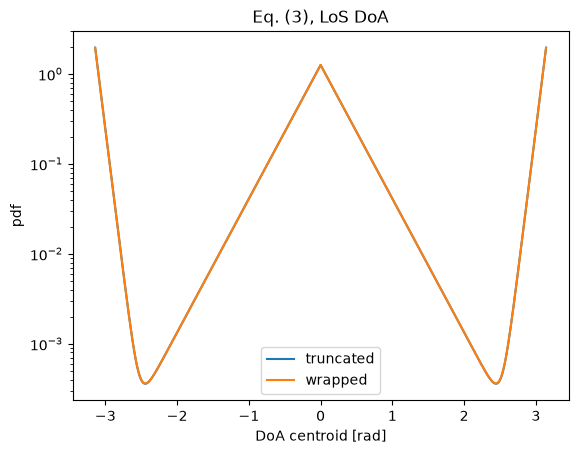

In [3]:
m = P.doa_centroid['los']; x = np.linspace(-np.pi, np.pi, 721)
for mode in ('truncated', 'wrapped'):
    plt.semilogy(x, D.bimodal_laplace_pdf(x, m.weights, m.centers, m.decays, mode), label=mode)
plt.xlabel('DoA centroid [rad]'); plt.ylabel('pdf'); plt.legend(); plt.title('Eq. (3), LoS DoA'); plt.show()

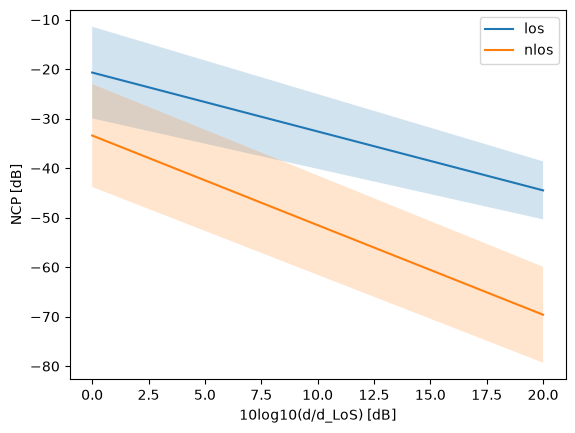

In [4]:
from channel_model.power_model import ncp_mean, ncp_std
x = np.linspace(0, 20, 50)
for k in ('los', 'nlos'):
    plt.plot(x, ncp_mean(x, P.power[k]), label=k); plt.fill_between(x, ncp_mean(x, P.power[k]) - ncp_std(x, P.power[k]), ncp_mean(x, P.power[k]) + ncp_std(x, P.power[k]), alpha=.2)
plt.xlabel('10log10(d/d_LoS) [dB]'); plt.ylabel('NCP [dB]'); plt.legend(); plt.show()